# Email Spam Detection using K-Nearest Neighbors (KNN) and Support Vector Machine (SVM)

**Aim:** Classify emails into two states using binary classification:

- **Normal State (Not Spam):** `0`
- **Abnormal State (Spam):** `1`

The practical uses the Kaggle `emails.csv` dataset and compares KNN and SVM using accuracy, precision, recall, F1-score, confusion matrices, Precision-Recall curves, and ROC curves.

**Dataset placement:** Keep `emails.csv` in the same folder as this notebook.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

pd.set_option('display.max_columns', 10)


## 2. Load the dataset

In [2]:
df = pd.read_csv('emails.csv')
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,...,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,...,0,0,0,0,0
1,Email 2,8,13,24,6,...,0,0,1,0,0
2,Email 3,0,0,1,0,...,0,0,0,0,0
3,Email 4,0,5,22,0,...,0,0,0,0,0
4,Email 5,7,6,17,1,...,0,0,1,0,0


## 3. Check missing values and dataset information

In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\\nDataset information:")
df.info()


Missing values in each column:
Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


## 4. Remove rows containing missing values

In [4]:
df = df.dropna(how='any').copy()
print("Shape after removing missing values:", df.shape)


Shape after removing missing values: (5172, 3002)


## 5. Separate input features and target

In [5]:
# The first column is the email identifier.
# The last column (Prediction) is the target:
# 0 = Normal / Not Spam, 1 = Abnormal / Spam.

x = df.iloc[:, 1:-1].values
y = df.iloc[:, -1].values

# Confirm that the feature columns contain numeric data
x = np.asarray(x, dtype=float)

print("Feature shape:", x.shape)
print("Target shape:", y.shape)
print("Target classes:", np.unique(y))
print("\\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())


Feature shape: (5172, 3000)
Target shape: (5172,)
Target classes: [0 1]
\nClass distribution:
0    3672
1    1500
Name: count, dtype: int64


## 6. Split the dataset into training and testing sets

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=10,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


Training data: (3879, 3000)
Testing data: (1293, 3000)


## 7. Define a function to evaluate the classifier

In [7]:
def report(classifier, model_name):
    y_pred = classifier.predict(x_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Normal (Not Spam)', 'Abnormal (Spam)']
    )
    display.plot(cmap='Blues', values_format='d')
    plt.title(model_name + ' - Confusion Matrix')
    plt.tight_layout()
    plt.show()

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    print(model_name, "Classification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Normal (Not Spam)', 'Abnormal (Spam)'],
        zero_division=0
    ))
    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Precision Score: {precision:.4f}")
    print(f"Recall Score:    {recall:.4f}")
    print(f"F1 Score:        {f1:.4f}")

    # These display classes work with predict_proba (KNN) or decision_function (SVM).
    PrecisionRecallDisplay.from_estimator(classifier, x_test, y_test)
    plt.title(model_name + ' - Precision-Recall Curve')
    plt.tight_layout()
    plt.show()

    RocCurveDisplay.from_estimator(classifier, x_test, y_test)
    plt.title(model_name + ' - ROC Curve')
    plt.tight_layout()
    plt.show()

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }


## 8. K-Nearest Neighbors (KNN) Classifier

In [8]:
kNN = KNeighborsClassifier(n_neighbors=10)
kNN.fit(x_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


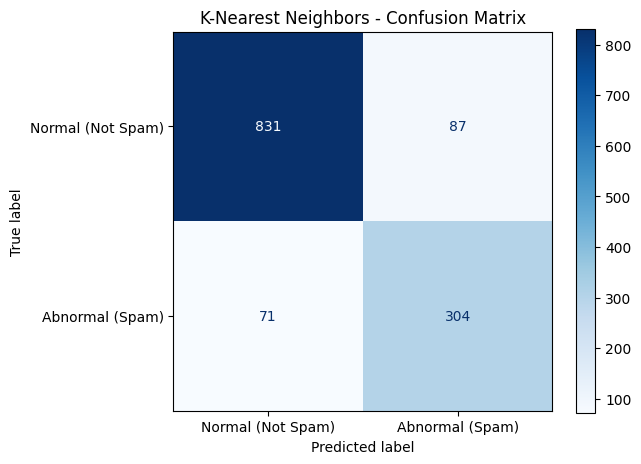

K-Nearest Neighbors Classification Report:
                   precision    recall  f1-score   support

Normal (Not Spam)       0.92      0.91      0.91       918
  Abnormal (Spam)       0.78      0.81      0.79       375

         accuracy                           0.88      1293
        macro avg       0.85      0.86      0.85      1293
     weighted avg       0.88      0.88      0.88      1293

Accuracy:        0.8778
Precision Score: 0.7775
Recall Score:    0.8107
F1 Score:        0.7937


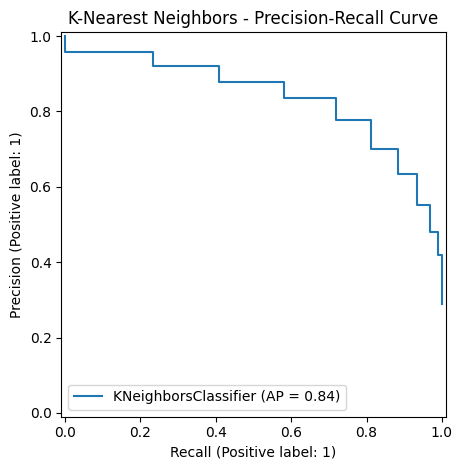

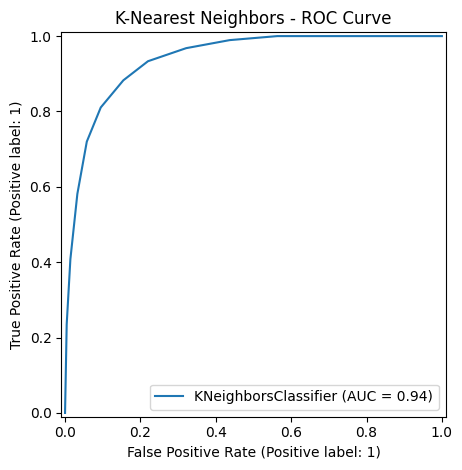

In [9]:
knn_results = report(kNN, 'K-Nearest Neighbors')


## 9. Support Vector Machine (SVM) Classifier

In [10]:
svm = SVC(gamma='auto', random_state=10)
svm.fit(x_train, y_train)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


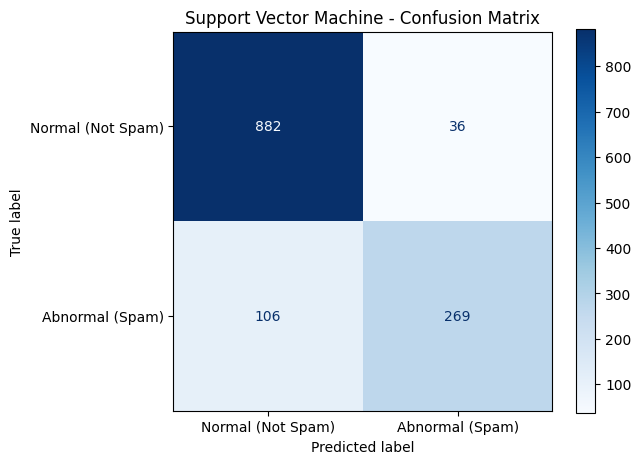

Support Vector Machine Classification Report:
                   precision    recall  f1-score   support

Normal (Not Spam)       0.89      0.96      0.93       918
  Abnormal (Spam)       0.88      0.72      0.79       375

         accuracy                           0.89      1293
        macro avg       0.89      0.84      0.86      1293
     weighted avg       0.89      0.89      0.89      1293

Accuracy:        0.8902
Precision Score: 0.8820
Recall Score:    0.7173
F1 Score:        0.7912


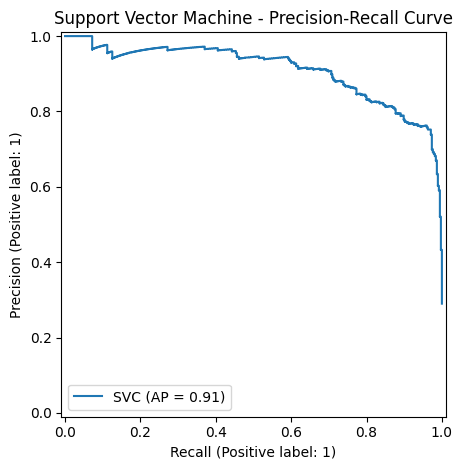

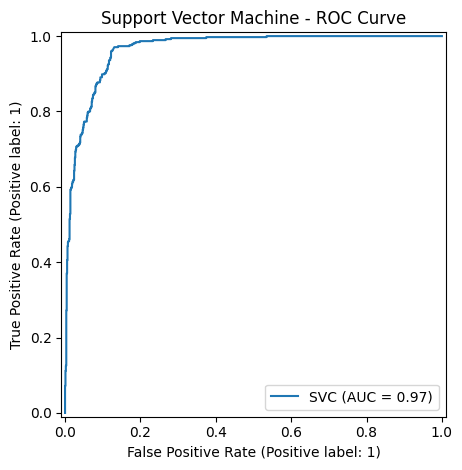

In [11]:
svm_results = report(svm, 'Support Vector Machine')


## 10. Compare the performance of KNN and SVM

In [12]:
comparison = pd.DataFrame([knn_results, svm_results])
comparison


,Model,Accuracy,Precision,Recall,F1-Score
0,K-Nearest Neighbors,0.877804,0.777494,0.810667,0.793734
1,Support Vector Machine,0.890178,0.881967,0.717333,0.791176


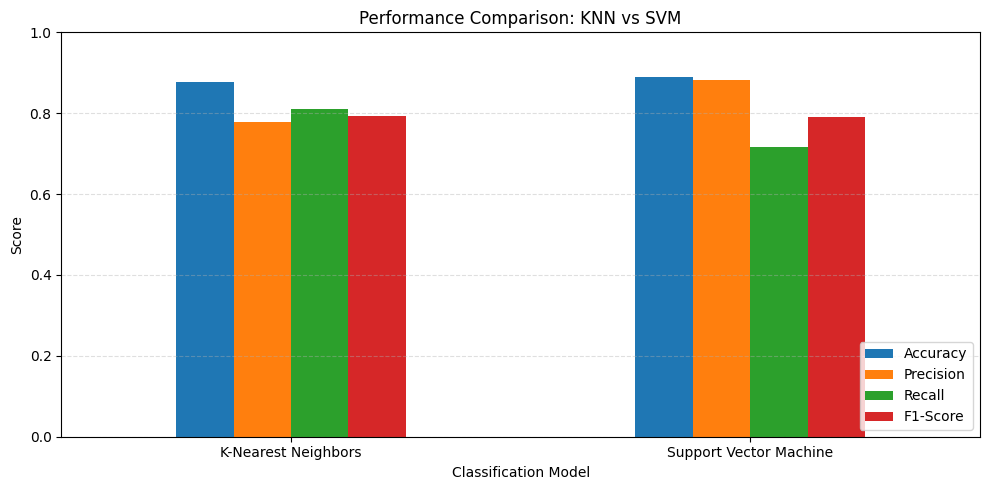

In [13]:
# Visual comparison of the evaluation metrics
comparison_plot = comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
]

comparison_plot.plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title('Performance Comparison: KNN vs SVM')
plt.ylabel('Score')
plt.xlabel('Classification Model')
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 11. Result and conclusion

The `emails.csv` dataset was classified into two categories:

- **Normal State (Not Spam):** 0
- **Abnormal State (Spam):** 1

K-Nearest Neighbors and Support Vector Machine classifiers were trained and tested. Their performance was evaluated using accuracy, precision, recall, F1-score, confusion matrices, Precision-Recall curves, and ROC curves.

**Conclusion:** Use the comparison table and plots generated above to identify which classifier performs better on this dataset. A higher accuracy or F1-score generally indicates better performance, while precision and recall are particularly useful for understanding spam detection errors. Do not decide the winning model before checking the actual results.